# 03 Model experiments
Reads `artifacts/metrics.json` written by `scripts/train.py`. Test period is a chronological hold-out; thresholds were chosen on validation only. **Synthetic data, so results are optimistic.**

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
from identitygraph.models.registry import load_json
rep = load_json('metrics.json')
print(rep['version'], rep['primary_model'], rep['data'])

0.1.0-202611122325 graph_gradient_boosting {'n_total': 20000, 'n_train': 12000, 'n_val': 4000, 'n_test': 4000, 'train_end': '2025-05-25 03:18:03.116360818', 'fraud_rate_test': 0.09425, 'synthetic': True}


In [2]:
rows = []
for name, r in rep['models'].items():
    for split in ('validation', 'test'):
        m = r[split]
        rows.append(dict(model=name, split=split, pr_auc=m['pr_auc'], roc_auc=m['roc_auc'], precision=m['precision'], recall=m['recall'], f1=m['f1'], recall_at_1pct_fpr=m['recall_at_1pct_fpr']))
tab = pd.DataFrame(rows)
tab[tab.split == 'test'].drop(columns='split').set_index('model').round(3)

,pr_auc,roc_auc,precision,recall,f1,recall_at_1pct_fpr
model,,,,,,
logistic_regression,0.755,0.897,0.759,0.692,0.724,0.509
random_forest,0.819,0.913,0.942,0.729,0.822,0.753
gradient_boosting,0.830,0.924,0.964,0.714,0.820,0.732
graph_gradient_boosting,0.827,0.919,0.889,0.740,0.808,0.745


split                     test  validation
model                                     
gradient_boosting        0.830       0.816
graph_gradient_boosting  0.827       0.805
logistic_regression      0.755       0.691
random_forest            0.819       0.818


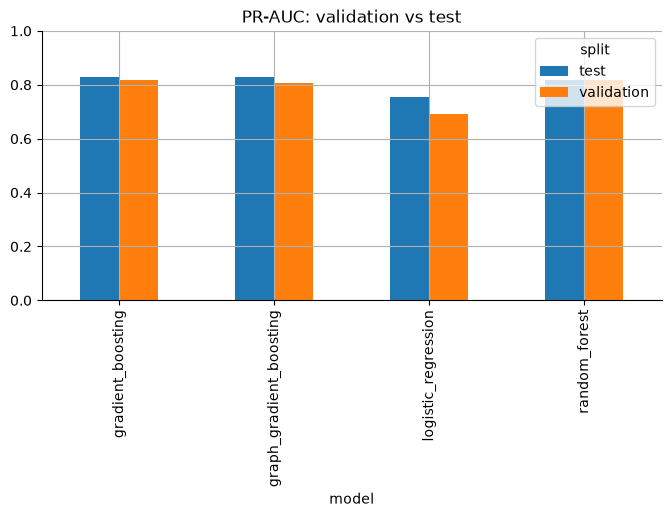

In [3]:
piv = tab.pivot(index='model', columns='split', values='pr_auc')
print(piv.round(3))
piv.plot.bar(title='PR-AUC: validation vs test'); plt.ylim(0, 1);

## Does the graph help?
Compare the graph-enhanced model with the same-family baseline.

In [4]:
b = rep['models']['gradient_boosting']['test']; g = rep['models']['graph_gradient_boosting']['test']
pd.DataFrame({'baseline GB': b, 'graph GB': g}).loc[['pr_auc', 'roc_auc', 'precision', 'recall', 'f1', 'recall_at_1pct_fpr']].round(3)

,baseline GB,graph GB
pr_auc,0.829552,0.827481
roc_auc,0.923639,0.919442
precision,0.964158,0.888535
recall,0.713528,0.740053
f1,0.820122,0.807525
recall_at_1pct_fpr,0.732095,0.745358


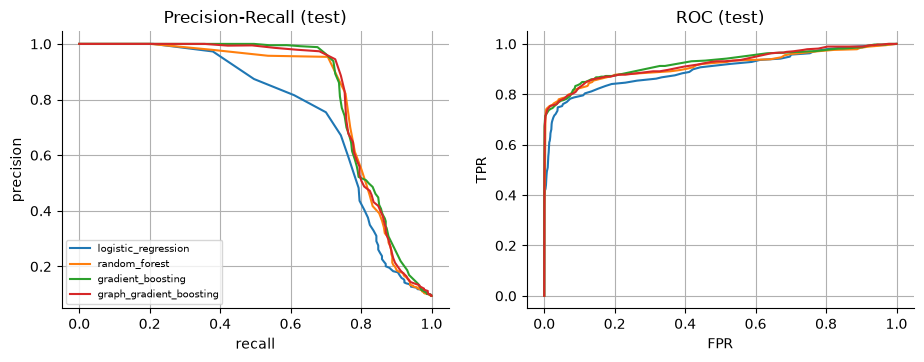

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for n, r in rep['models'].items():
    p = np.array(r['curves_test']['pr']); axs[0].plot(p[:, 0], p[:, 1], label=n)
    c = np.array(r['curves_test']['roc']); axs[1].plot(c[:, 0], c[:, 1], label=n)
axs[0].set(title='Precision-Recall (test)', xlabel='recall', ylabel='precision'); axs[1].set(title='ROC (test)', xlabel='FPR', ylabel='TPR'); axs[0].legend(fontsize=7);

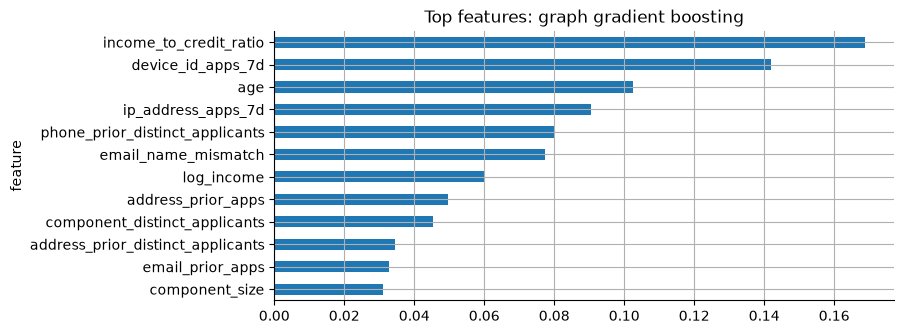

In [6]:
fi = pd.DataFrame(rep['models']['graph_gradient_boosting']['feature_importance']).set_index('feature')
fi.head(12).plot.barh(legend=False, title='Top features: graph gradient boosting').invert_yaxis();

In [7]:
cm = rep['models'][rep['primary_model']]['test']['confusion_matrix']; print(rep['primary_model'], cm)
print('thresholds (validation-selected):', rep['models'][rep['primary_model']]['thresholds'])

graph_gradient_boosting {'tn': 3588, 'fp': 35, 'fn': 98, 'tp': 279}
thresholds (validation-selected): {'medium': 0.013638140181830948, 'high': 0.22581369680780217, 'selected_on': 'validation'}


**Caveats:** single seed, no confidence intervals, uncalibrated scores, synthetic fraud patterns with explicit signals.